<p style="height:100px;line-height:100px;background-color:cyan;text-align:center;font-size:52px;font-family:serif;font-weight:bold;color:black;border-radius:12px;">
    Loan Default - Analytics
</p>

# **1.**
<p style="height:80px;line-height:80px;background-color:lime;padding-left:12px;font-size:36px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:10px;">
    Importing Libraries & Data
</p>

In [1]:
# data
import numpy as np
import polars as pl
import polars.selectors as cs
# stats
import scipy.stats as ss
# graph
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pl.read_csv('Datasets/Loan_default.csv')

# **2.**
<p style="height:80px;line-height:80px;background-color:lime;padding-left:12px;font-size:36px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:10px;">
    Exploring Data
</p>

**Reading**

**Exploring**

In [3]:
df.shape

(255347, 18)

In [4]:
df.select(pl.all().approx_n_unique())

LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
256439,52,115266,158303,549,120,4,2289,5,81,4,4,3,2,2,5,2,2


In [5]:
df.null_count()

LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [6]:
df.select(cs.numeric()).describe()

statistic,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",255347.0,255347.0,255347.0,255347.0,255347.0,255347.0,255347.0,255347.0,255347.0,255347.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
"""std""",14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.96933,0.230917,0.320379
"""min""",18.0,15000.0,5000.0,300.0,0.0,1.0,2.0,12.0,0.1,0.0
"""25%""",31.0,48826.0,66156.0,437.0,30.0,2.0,7.77,24.0,0.3,0.0
"""50%""",43.0,82466.0,127556.0,574.0,60.0,2.0,13.46,36.0,0.5,0.0
"""75%""",56.0,116219.0,188986.0,712.0,90.0,3.0,19.25,48.0,0.7,0.0
"""max""",69.0,149999.0,249999.0,849.0,119.0,4.0,25.0,60.0,0.9,1.0


In [7]:
df.head()

LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
str,i64,i64,i64,i64,i64,i64,f64,i64,f64,str,str,str,str,str,str,str,i64
"""I38PQUQS96""",56,85994,50587,520,80,4,15.23,36,0.44,"""Bachelor's""","""Full-time""","""Divorced""","""Yes""","""Yes""","""Other""","""Yes""",0
"""HPSK72WA7R""",69,50432,124440,458,15,1,4.81,60,0.68,"""Master's""","""Full-time""","""Married""","""No""","""No""","""Other""","""Yes""",0
"""C1OZ6DPJ8Y""",46,84208,129188,451,26,3,21.17,24,0.31,"""Master's""","""Unemployed""","""Divorced""","""Yes""","""Yes""","""Auto""","""No""",1
"""V2KKSFM3UN""",32,31713,44799,743,0,3,7.07,24,0.23,"""High School""","""Full-time""","""Married""","""No""","""No""","""Business""","""No""",0
"""EY08JDHTZP""",60,20437,9139,633,8,4,6.51,48,0.73,"""Bachelor's""","""Unemployed""","""Divorced""","""No""","""Yes""","""Auto""","""No""",0


In [8]:
X_df = df.select(pl.col(df.columns[1:-1]))
y_df = df.select(pl.col('Default'))

## **2.1**
<p style="height:60px;line-height:60px;background-color:navy;padding-left:12px;font-size:32px;font-family:serif;font-weight:bold;color:white;border:1px outset gold;border-radius:8px;">
    Variables
</p>

### **2.1.1**
<p style="height:40px;line-height:40px;background-color:yellow;padding-left:12px;font-size:24px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    Age
</p>

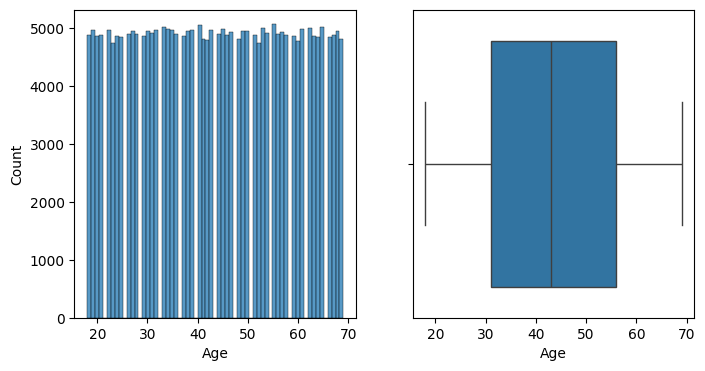

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4))

sns.histplot(data=df, x='Age', ax=axs[0])
sns.boxplot(data=df, x='Age', ax=axs[1])

plt.show()

**NOTE**
>  .

### **2.1.2**
<p style="height:40px;line-height:40px;background-color:yellow;padding-left:12px;font-size:24px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    Income
</p>

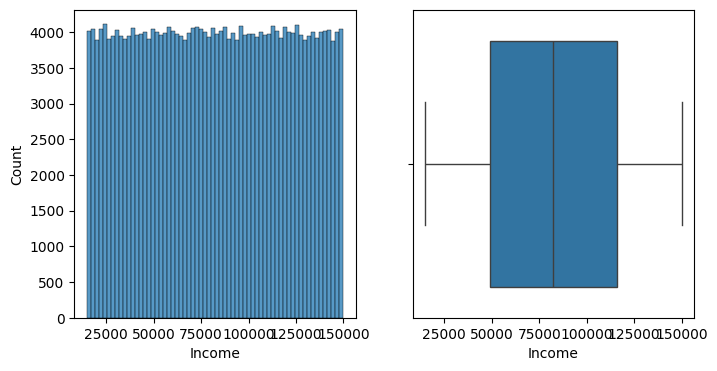

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4))

sns.histplot(data=df, x='Income', ax=axs[0])
sns.boxplot(data=df, x='Income', ax=axs[1])

plt.show()

**NOTE**
>  .

### **2.1.3**
<p style="height:40px;line-height:40px;background-color:yellow;padding-left:12px;font-size:24px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    LoanAmount
</p>

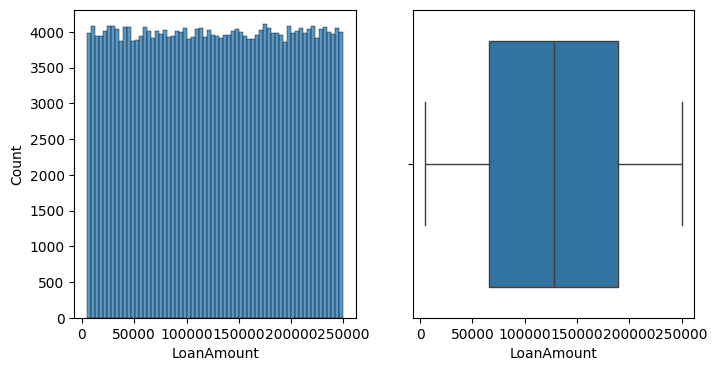

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4))

sns.histplot(data=df, x='LoanAmount', ax=axs[0])
sns.boxplot(data=df, x='LoanAmount', ax=axs[1])

plt.show()

**NOTE**
>  .

### **2.1.4**
<p style="height:40px;line-height:40px;background-color:yellow;padding-left:12px;font-size:24px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    CreditScore
</p>

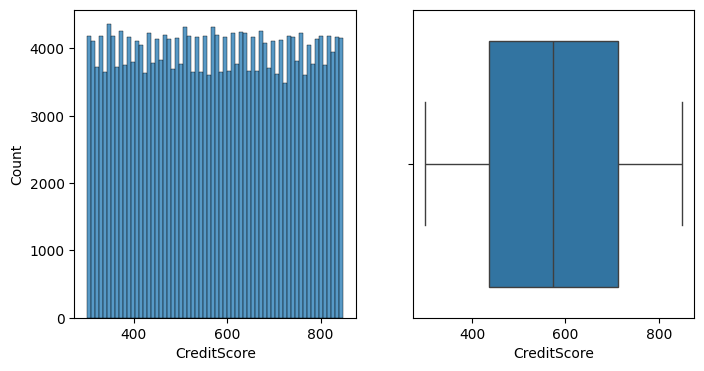

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4))

sns.histplot(data=df, x='CreditScore', ax=axs[0])
sns.boxplot(data=df, x='CreditScore', ax=axs[1])

plt.show()

**NOTE**
>  .

## **2.1**
<p style="height:60px;line-height:60px;background-color:navy;padding-left:12px;font-size:32px;font-family:serif;font-weight:bold;color:white;border:1px outset gold;border-radius:8px;">
    
</p>

### **2.1.1**
<p style="height:40px;line-height:40px;background-color:yellow;padding-left:12px;font-size:28px;font-family:serif;font-weight:bold;color:black;border:1px outset gold;border-radius:6px;">
    
</p>

# **Kaggle : [Tarek Ghajary](www.kaggle.com/tarekghajary) | GitHub : [CHESyrian](www.github.com/CHESyrian) | Linkedin : [Tarek Ghajary](https://www.linkedin.com/in/tarek-ghajary-95ab0b195/)**
<p style="height:240px;line-height:100px;font-size:64px;background-color:cyan;color:white;padding:20px auto;text-align:center;border:2px outset gold;border-radius:8px;">
    Created by:<br/> <code style="border:1px outset gold;border-radius:10px;">Tarek Ghajary</code>
</p>